# alftrade Demo

A pedagogical **A-share low-frequency cross-sectional trading system** (daily signal frequency) that mirrors the layered architecture of `hftrade` but adapts every layer to the multi-stock daily setting.

**Architecture:**
```
DailyBar[s]  →  FactorCalculator[s].update(bar)         (per-stock rolling state)
                     ↓
              cross-sectional standardization (z-score within universe)
                     ↓
              TradingEngine.on_cross_section(date, bars) → {symbol: [Signal]}
                     ↓
              SignalAggregator.aggregate_all()           → {symbol: CompositeSignal}
                     ↓
              PortfolioManager.decide() — rank top-N, target weights, rebalance
                   ↓                ↓
            RiskManager        RiskManager
            .check_pre_trade() .check_post_bar()
              (T+1 / limit /    (stop-loss / drawdown /
               lot / conc.)      daily-loss)
                ↓                    ↓
              [Trade] → Portfolio.apply_trade() → PnL
```

**A-share specifics modelled:**
- Long-only (no shorting)
- T+1 settlement (buys locked for one trading day)
- ±10% daily price-limit (reject buys at limit-up, sells at limit-down)
- 100-share board lot (buys rounded to multiples of 100)
- Transaction costs: commission (2.5 bps both ways, 5-yuan min) + stamp duty (10 bps on sells)
- Cross-sectional Fama-MacBeth Ridge calibration

**Sections:**
- Part I (§1–§7): Factor computation, cross-sectional signals, Fama-MacBeth calibration, factor profiling
- Part II (§8–§11): Portfolio rebalancing, equity curve, A-share risk controls, full calibrated pipeline


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from alftrade import (
    DailyBar, StockUniverse, generate_simulated_market,
    FactorCalculator, FACTOR_NAMES,
    Signal, TradingEngine,
    Position, Trade, Portfolio, CostModel, CompositeSignal,
    SignalAggregator, PortfolioManager,
    RiskManager, RiskConfig,
    CalibrationResult, FactorCalibrator,
    FactorProfile, ModelProfile, FactorProfiler,
)

plt.rcParams["figure.dpi"] = 110
np.random.seed(42)
print("alftrade ready —", len(FACTOR_NAMES), "factors available")

alftrade ready — 11 factors available


---

# Part I — Factors & Signals

## 1. Direct Factor Computation

The `FactorCalculator` maintains per-stock rolling state (price/volume windows, Wilder RSI & ATR). Feed it one `DailyBar` at a time and it returns the 10 daily factors. Unlike `hftrade`'s C++ calculator, all factors are **already stationary** (returns, ratios, bounded indicators) — no price levels leak in.

In [2]:
calc = FactorCalculator()

# Build a synthetic bar: close=10.5, prev_close=10.0
from alftrade.data import compute_limit_prices
up, dn = compute_limit_prices(10.0, 0.10)
bar = DailyBar(
    date=20200101, symbol="000001.SZ",
    open=10.05, high=10.60, low=10.00, close=10.50,
    volume=1_200_000, amount=12_600_000,
    prev_close=10.0, limit_up_price=up, limit_down_price=dn,
    total_shares=500_000_000,
)

factors = calc.update(bar)
for name in FACTOR_NAMES:
    print(f"  {name:<16s} = {factors[name]:+.6f}")

  daily_return     = +0.050000
  overnight_return = +0.005000
  intraday_return  = +0.044776
  momentum_5d      = +0.000000
  momentum_20d     = +0.000000
  ma_dev_20        = +0.000000
  volatility_20d   = +0.000000
  volume_ratio     = +1.000000
  rsi_14           = +0.000000
  atr_pct_14       = +0.057143
  market_beta      = +1.000000


### Factor definitions

| Factor | Formula | Interpretation |
|--------|---------|---------------|
| `daily_return` | (close − prev_close) / prev_close | Close-to-close return |
| `overnight_return` | (open − prev_close) / prev_close | Overnight gap |
| `intraday_return` | (close − open) / open | In-session return |
| `momentum_5d` | (close − close[t-5]) / close[t-5] | 5-day reversal signal |
| `momentum_20d` | (close − close[t-20]) / close[t-20] | 20-day momentum |
| `ma_dev_20` | (close − SMA20) / SMA20 | Deviation from 20d average |
| `volatility_20d` | std(daily_return, 20) | 20-day return volatility |
| `volume_ratio` | volume / SMA(volume, 20) | Relative turnover |
| `rsi_14` | (RSI14 − 50) / 50, ∈ [−1, +1] | Rescaled Wilder RSI |
| `atr_pct_14` | ATR14 / close | Normalized average true range |

## 2. Streaming Daily Bars — Factor Evolution

Feed 80 days of one stock's bars through a calculator and watch the rolling factors fill in.

In [3]:
# Generate a small panel and pick one stock to inspect.
bars_by_date, universe, _mkt = generate_simulated_market(n_stocks=5, n_days=120, seed=3)
dates = sorted(bars_by_date)
sym = universe.symbols[0]

calc = FactorCalculator()
history = {k: [] for k in FACTOR_NAMES}
closes = []

for d in dates:
    f = calc.update(bars_by_date[d][sym])
    closes.append(bars_by_date[d][sym].close)
    for k in FACTOR_NAMES:
        history[k].append(f[k])

print(f"Tracked {sym} over {len(dates)} days; close went "
      f"{closes[0]:.2f} → {closes[-1]:.2f}")

Tracked 600000.SH over 120 days; close went 34.84 → 59.13


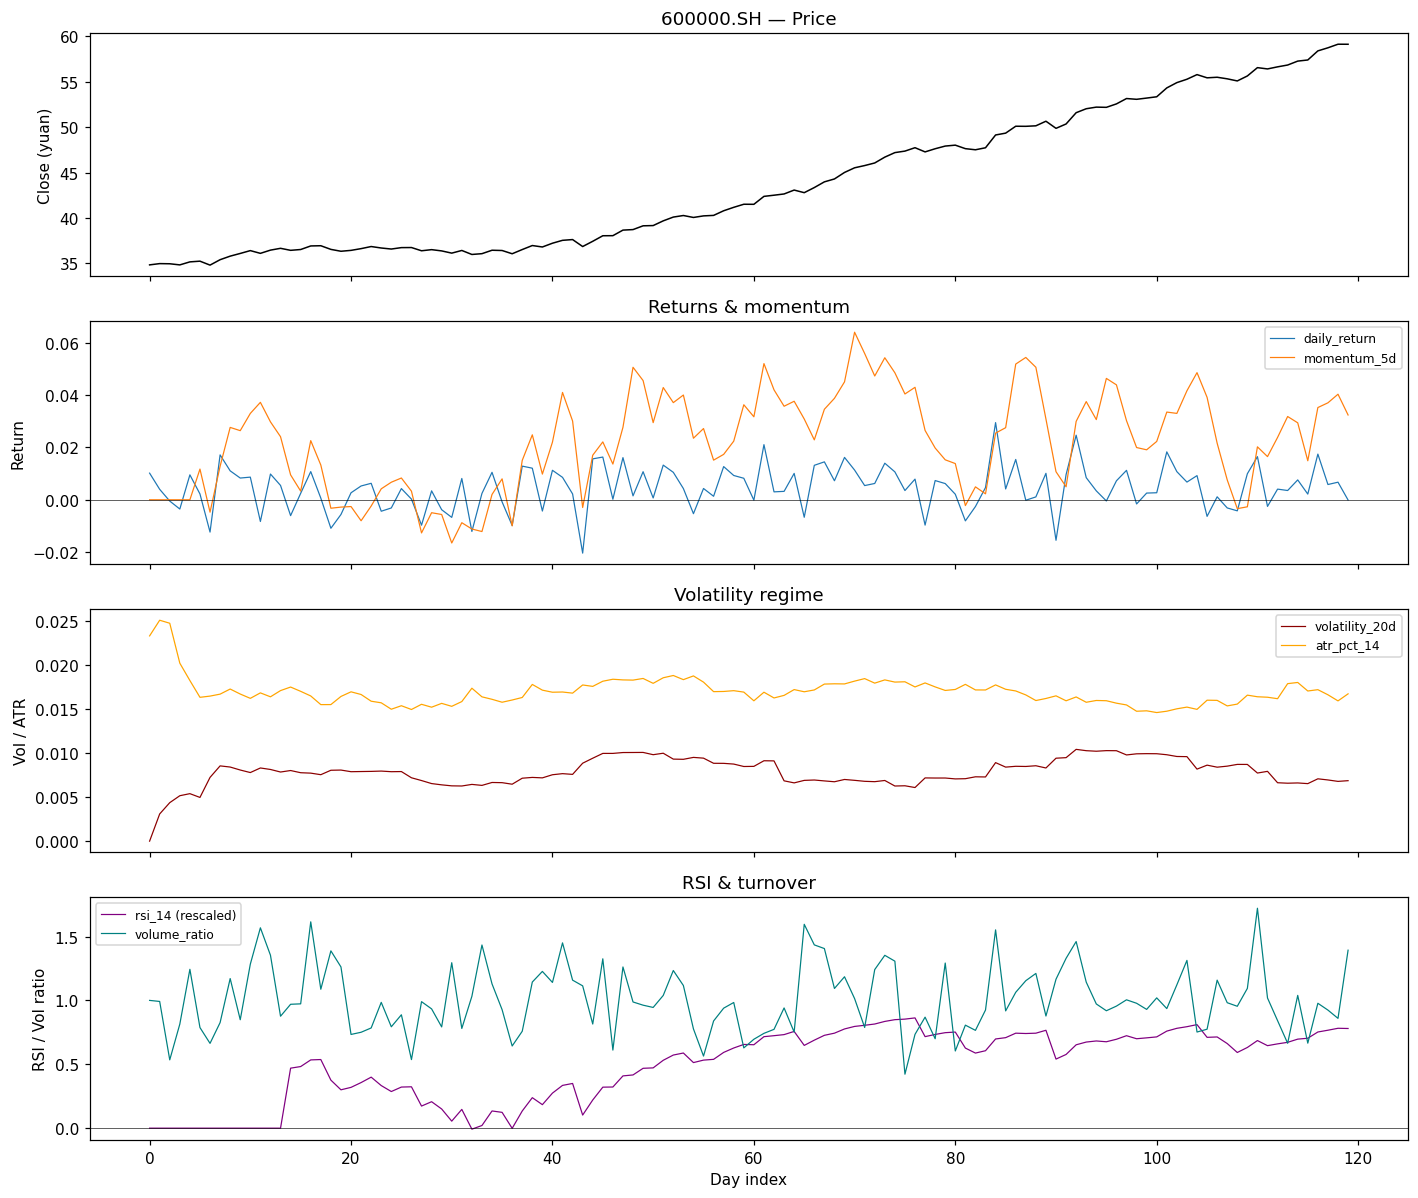

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)

x = range(len(dates))
axes[0].plot(x, closes, linewidth=1.0, color="black")
axes[0].set_ylabel("Close (yuan)")
axes[0].set_title(f"{sym} — Price")

axes[1].plot(x, history["daily_return"], linewidth=0.8, label="daily_return")
axes[1].plot(x, history["momentum_5d"], linewidth=0.8, label="momentum_5d")
axes[1].axhline(0, color="k", linewidth=0.4)
axes[1].set_ylabel("Return")
axes[1].set_title("Returns & momentum")
axes[1].legend(fontsize=8)

axes[2].plot(x, history["volatility_20d"], linewidth=0.8, color="darkred", label="volatility_20d")
axes[2].plot(x, history["atr_pct_14"], linewidth=0.8, color="orange", label="atr_pct_14")
axes[2].set_ylabel("Vol / ATR")
axes[2].set_title("Volatility regime")
axes[2].legend(fontsize=8)

axes[3].plot(x, history["rsi_14"], linewidth=0.8, color="purple", label="rsi_14 (rescaled)")
axes[3].plot(x, history["volume_ratio"], linewidth=0.8, color="teal", label="volume_ratio")
axes[3].axhline(0, color="k", linewidth=0.4)
axes[3].set_ylabel("RSI / Vol ratio")
axes[3].set_xlabel("Day index")
axes[3].set_title("RSI & turnover")
axes[3].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 3. Cross-Sectional Standardization

A-share daily strategies compare stocks *to each other* on each date, not to their own history. The engine z-scores every factor **within the day's universe** before applying calibration β — this removes day-to-day scale drift and makes β interpretable as "per-1σ cross-sectional exposure".

The same standardization must be applied identically in offline calibration (`fit`) and online inference (`_calibrated_signals`).

In [5]:
# Show one date's raw factors vs standardized
engine = TradingEngine()
d = dates[-1]
cs = engine.build_cross_section(d, bars_by_date[d])

print(f"Date {d}: {len(cs.symbols)} stocks")
print()
print(f"  {'Stock':<12s}  raw momentum_5d   z(momentum_5d)")
print(f"  {'-'*12}  {'-'*16}  {'-'*16}")
for i, sym in enumerate(cs.symbols):
    raw = cs.factors_by_symbol[sym]["momentum_5d"]
    z = cs.z_matrix[i, FACTOR_NAMES.index("momentum_5d")]
    print(f"  {sym:<12s}  {raw:+.6f}        {z:+.4f}")

Date 20200220: 5 stocks

  Stock         raw momentum_5d   z(momentum_5d)
  ------------  ----------------  ----------------
  600000.SH     +0.000000        +0.0000
  600001.SH     +0.000000        +0.0000
  600002.SH     +0.000000        +0.0000
  600003.SH     +0.000000        +0.0000
  600004.SH     +0.000000        +0.0000


## 4. Signal Generation — Raw Mode

In **raw mode** (no calibration), the engine applies per-factor threshold rules. Each factor that exceeds its threshold fires one `Signal`. This is useful for inspection and as a baseline before calibration.

Long-only convention: a positive factor reading → `LONG` (direction=+1); a negative reading → `FLAT` (direction=0), never `SHORT`.

In [6]:
engine_raw = TradingEngine(raw_thresholds={
    "momentum_5d": 0.02,
    "rsi_14": 0.30,
    "ma_dev_20": 0.02,
})

out = engine_raw.on_cross_section(d, bars_by_date[d])
print(f"Date {d}: {len(out)} stocks have signals")
print()
for sym, sigs in list(out.items())[:6]:
    for s in sigs:
        print(f"  {s}")

Date 20200220: 0 stocks have signals



---

## 5. Factor Calibration — Fama-MacBeth Cross-Sectional Ridge

### Why Fama-MacBeth (not one pooled regression)?

A pooled regression stacks every (date, stock) pair and runs one Ridge. Its standard errors assume residuals are independent across dates — which they are not. Fama-MacBeth (1973) fixes this:

1. Run a **separate** cross-sectional Ridge regression per date: β_t = (X_t'X_t + αI)⁻¹ X_t'y_t
2. Report β̄ = mean_t(β_t) and t = mean_t(β_t) / (std_t(β_t) / √T)

The time-series variation of β_t itself drives significance — the standard estimator in equity factor research.

### Two-phase usage (mirrors hftrade)

**Phase 1:** walk historical bars, pair each date's factors with the realized N-day forward return.
**Phase 2:** fit and hand the result to the engine + aggregator.

In [7]:
# Generate a larger panel for calibration
bars_full, uni_full, _mkt_full = generate_simulated_market(n_stocks=30, n_days=250, seed=7)
dates_full = sorted(bars_full)
split = dates_full[:-30]   # train on first 220 days

# Dedicated offline engine (its per-symbol calculators persist across dates)
offline_engine = TradingEngine()
calibrator = FactorCalibrator(horizon=5, alpha=1.0, min_samples=50, min_dates=10)

for d in split:
    cs = offline_engine.build_cross_section(d, bars_full[d])
    calibrator.collect(d, cs, bars_full)

print(f"Collected {calibrator.num_samples} (date, stock) pairs across {calibrator.num_dates} dates")
print(f"Ready to fit: {calibrator.ready}")

Collected 6450 (date, stock) pairs across 215 dates
Ready to fit: True


In [8]:
result = calibrator.fit(method="fama_macbeth")
print(result)

CalibrationResult(horizon=5, method=fama_macbeth, alpha=1.0, n=6450, T=215, R²=0.2397), date=2026-07-24T08:00:11.890776+00:00
  Factor                 Beta   t-stat       IC       IR
  ---------------- ---------- -------- -------- --------
  daily_return       -0.00080    -2.76  -0.0064   -0.045
  overnight_return   -0.00022    -0.50  -0.0116   -0.074
  intraday_return    -0.00068    -2.44  -0.0027   -0.023
  momentum_5d        -0.00238    -3.40   0.0608    0.297
  momentum_20d       -0.00097    -1.24   0.1318    0.699
  ma_dev_20           0.00169     1.91   0.1286    0.686
  volatility_20d     -0.00464    -6.41  -0.2287   -1.116
  volume_ratio        0.00073     1.76   0.0216    0.132
  rsi_14              0.00209     2.47   0.1455    0.815
  atr_pct_14         -0.00292    -3.78  -0.2181   -1.118
  market_beta        -0.00062    -1.47  -0.0602   -0.328


### Reading the calibration output

| Column | Meaning | Good value |
|--------|---------|------------|
| `Beta` | FM-averaged cross-sectional Ridge coefficient | Large \|β\| with correct sign |
| `t-stat` | FM t-statistic = β̄ / (std(β_t)/√T) | \|t\| > 2 is conventionally significant |
| `IC` | Pooled Pearson corr(factor, y) | \|IC\| > 0.03 is live-tradeable in A-shares |
| `IR` | Information Ratio = mean(IC_t) / std(IC_t) | \|IR\| > 0.5 is a consistent factor |

The simulator embeds a **negative volatility loading** (low-vol anomaly) and **negative 5-day momentum** (short-term reversal) — both classic A-share effects. Check that the calibrator recovers them with the correct sign and high significance.

---

## 6. Factor Profiler — Which factors are actually good?

While `CalibrationResult` gives β and IC for *building* signals, `FactorProfiler` evaluates factor **quality**: quantile returns, monotonicity, turnover, coverage, and partial R² contribution.

In [9]:
profiler = FactorProfiler.from_calibrator(calibrator, n_quantiles=5)
model_profile = profiler.profile()
print(model_profile)

ModelProfile(n=6450, T=215, k=11, model_IC=0.2473, model_mono=1.0000, L−S=0.02545)
  Factor                 Beta    t-stat         IC      IR       L−S   turn    mono
  ---------------- ---------- ---------    ------- ------- --------- ------ -------
  daily_return     β=  -0.00080 t=  -2.76**  IC=-0.0064 IR= -0.045 L−S=-0.00111 turn= 0.340 mono= -0.100
  overnight_return β=  -0.00022 t=  -0.50    IC=-0.0116 IR= -0.074 L−S=-0.00202 turn= 0.344 mono= -0.400
  intraday_return  β=  -0.00068 t=  -2.44*   IC=-0.0027 IR= -0.023 L−S=-0.00078 turn= 0.340 mono= -0.100
  momentum_5d      β=  -0.00238 t=  -3.40*** IC= 0.0608 IR=  0.297 L−S= 0.00569 turn= 0.150 mono=  0.700
  momentum_20d     β=  -0.00097 t=  -1.24    IC= 0.1318 IR=  0.699 L−S= 0.01113 turn= 0.065 mono=  0.900
  ma_dev_20        β=   0.00169 t=   1.91    IC= 0.1286 IR=  0.686 L−S= 0.01234 turn= 0.091 mono=  1.000
  volatility_20d   β=  -0.00464 t=  -6.41*** IC=-0.2287 IR= -1.116 L−S=-0.02214 turn= 0.048 mono= -1.000
  volume_ratio

### Quantile analysis — visualizing factor monotonicity

For a good cross-sectional factor, mean forward return should increase (or decrease) monotonically across quantiles sorted by factor value. The **long-short spread** (top − bottom quantile) is the single-number summary of a factor's payoff.

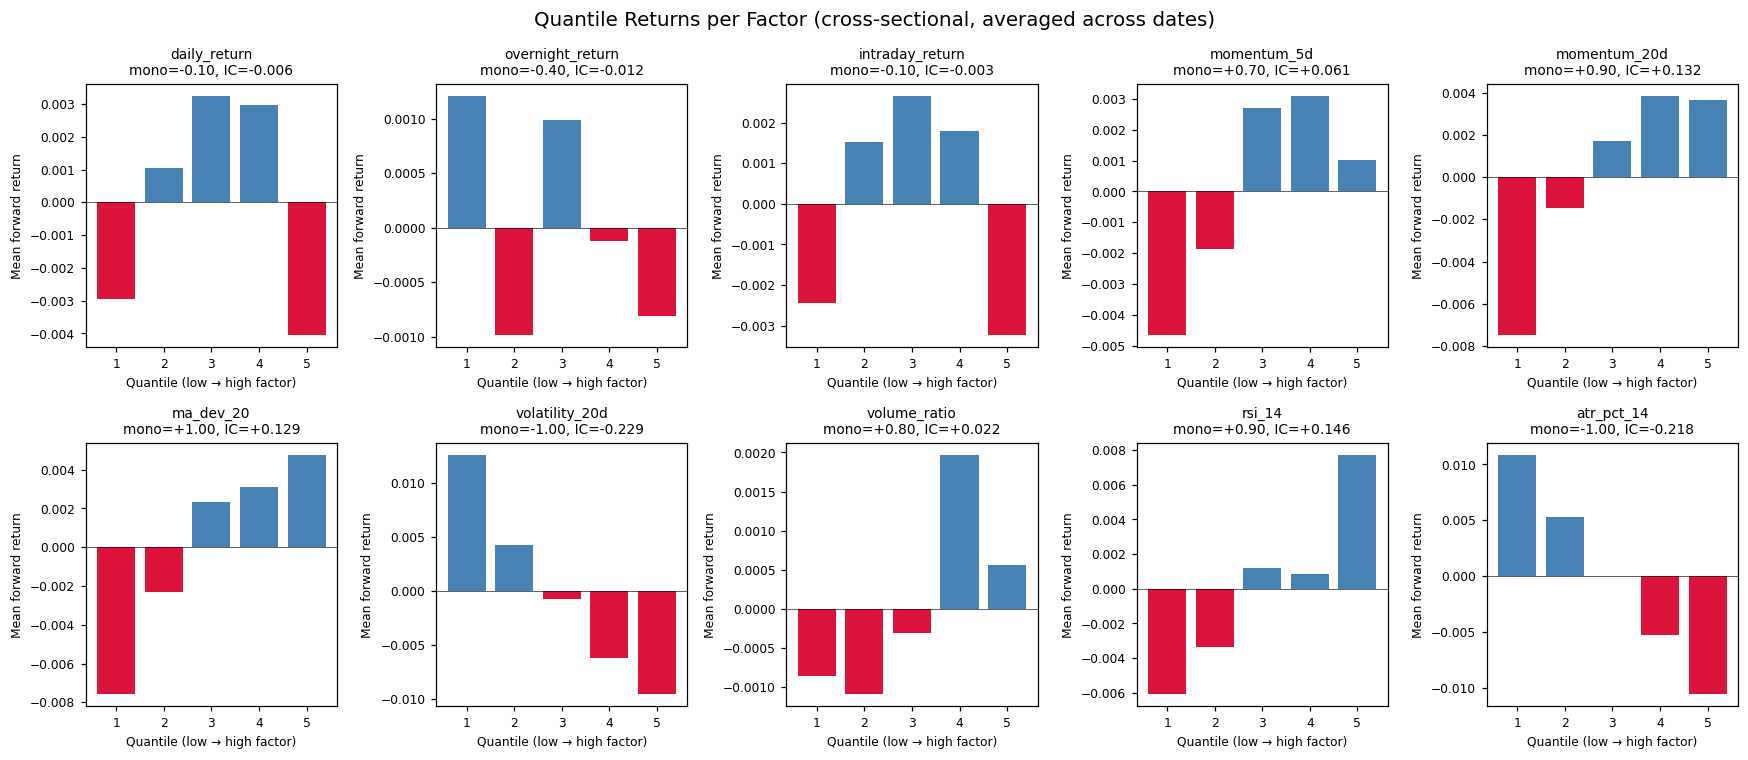

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for ax, fp in zip(axes.flat, model_profile.factor_profiles):
    if fp.quantile_returns:
        qs = range(1, len(fp.quantile_returns) + 1)
        colors = ["crimson" if r < 0 else "steelblue" for r in fp.quantile_returns]
        ax.bar(qs, fp.quantile_returns, color=colors)
        ax.set_title(f"{fp.name}\nmono={fp.monotonicity:+.2f}, IC={fp.ic:+.3f}", fontsize=9)
        ax.set_xlabel("Quantile (low → high factor)", fontsize=8)
        ax.set_ylabel("Mean forward return", fontsize=8)
        ax.axhline(0, color="k", linewidth=0.4)
        ax.tick_params(labelsize=8)
    else:
        ax.set_visible(False)

plt.suptitle("Quantile Returns per Factor (cross-sectional, averaged across dates)", fontsize=13)
plt.tight_layout()
plt.show()

### Model-level monotonicity — does the model rank correctly?

The model predicts a forward return per stock: ŷ = Σ β_k · z(factor_k). A good model's predicted ranking should match actual returns across quantiles. `model_monotonicity` is the Spearman rank correlation between quantile index and mean actual return.

In [11]:
print(f"Model IC:            {model_profile.model_ic:+.4f}")
print(f"Model monotonicity:  {model_profile.model_monotonicity:+.4f}")
print(f"Long-short spread:   {model_profile.long_short_spread:+.5f}")
print()
print("Model quantile returns (low → high predicted return):")
for i, r in enumerate(model_profile.model_quantile_returns, 1):
    print(f"  Q{i}: {r:+.5f}")

Model IC:            +0.2473
Model monotonicity:  +1.0000
Long-short spread:   +0.02545

Model quantile returns (low → high predicted return):
  Q1: -0.01204
  Q2: -0.00492
  Q3: +0.00026
  Q4: +0.00357
  Q5: +0.01341


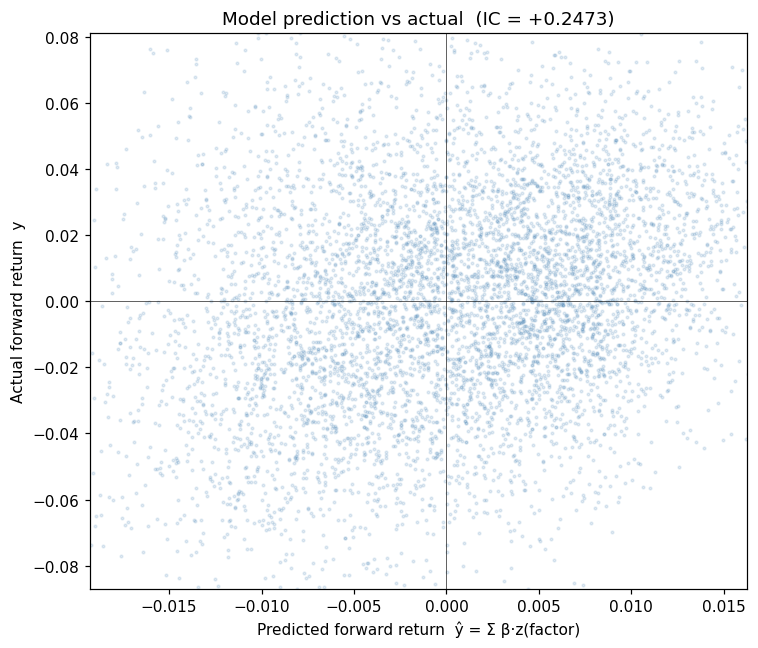

In [12]:
# y_pred vs y scatter with quantile overlay
betas = np.array([result.betas.get(n, 0.0) for n in FACTOR_NAMES])

# Rebuild the full panel of (z, y) to scatter
X_all = np.vstack([calibrator._by_date[d][0] for d in sorted(calibrator._by_date)])
y_all = np.concatenate([calibrator._by_date[d][1] for d in sorted(calibrator._by_date)])
y_pred = X_all @ betas

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_pred, y_all, s=3, alpha=0.15, color="steelblue")
ax.axhline(0, color="k", linewidth=0.4)
ax.axvline(0, color="k", linewidth=0.4)
ax.set_xlabel("Predicted forward return  ŷ = Σ β·z(factor)")
ax.set_ylabel("Actual forward return  y")
ax.set_title(f"Model prediction vs actual  (IC = {model_profile.model_ic:+.4f})")
lo, hi = np.percentile(y_pred, [1, 99])
ax.set_xlim(lo, hi)
ax.set_ylim(np.percentile(y_all, [1, 99]))
plt.tight_layout()
plt.show()

---

# Part II — Portfolio & Risk

## 8. From Signals to Portfolio

The `PortfolioManager` converts per-stock signals into a target portfolio:

1. **Aggregate** each stock's signals into one composite score.
2. **Rank** stocks by score; pick the top `n_holdings` with positive score.
3. **Assign target weights** (equal-weight or score-weighted).
4. **Generate trades**: sells first (free cash), then buys (capped by cash, rounded to board lot).
5. **Risk gate**: each trade passes through `RiskManager.check_pre_trade`.
6. **Post-bar monitor**: `check_post_bar` may force-close positions.

In [13]:
# Use the calibration result from §5
live_engine = TradingEngine(calibration=result)
aggregator = SignalAggregator(calibration=result)

pm = PortfolioManager(
    capital=1_000_000.0,
    n_holdings=5,
    weighting="equal",
    aggregator=aggregator,
)

# Run the first held-out day
d0 = dates_full[-30]
sigs = live_engine.on_cross_section(d0, bars_full[d0])
trades = pm.decide(d0, bars_full[d0], sigs)

print(f"Date {d0}: {len(trades)} trades executed")
print()
for t in trades:
    print(f"  {t}")
print()
n_pos = sum(1 for p in pm.portfolio.positions.values() if p.quantity > 0)
equity = pm.portfolio.mark_to_market(bars_full[d0])
print(f"Positions open: {n_pos}  |  Equity: {equity:,.0f}")

Date 20200321: 5 trades executed

  Trade(20200321 600020.SH OPEN qty=+9000 @ 22.12 cost=53.75 pnl=0.00 [REBALANCE])
  Trade(20200321 600015.SH OPEN qty=+2900 @ 67.24 cost=52.65 pnl=0.00 [REBALANCE])
  Trade(20200321 600000.SH OPEN qty=+2800 @ 70.36 cost=53.19 pnl=0.00 [REBALANCE])
  Trade(20200321 600011.SH OPEN qty=+4400 @ 45.11 cost=53.59 pnl=0.00 [REBALANCE])
  Trade(20200321 600001.SH OPEN qty=+9300 @ 21.31 cost=53.50 pnl=0.00 [REBALANCE])

Positions open: 5  |  Equity: 999,733


## 9. Equity Curve — Running the Full Pipeline Over Time

Walk the held-out 30 days through the calibrated pipeline and track equity, position count, and cash.

In [14]:
pm = PortfolioManager(
    capital=1_000_000.0,
    n_holdings=5,
    weighting="equal",
    aggregator=SignalAggregator(calibration=result),
)
live_engine = TradingEngine(calibration=result)

held_out = dates_full[-30:]
equity_hist, cash_hist, npos_hist, realized_hist, unrealized_hist = [], [], [], [], []

# Per-date cross-sectional records for §9a/§9b visualizations:
#   score_matrix[t, i]  = predicted return of stock i on date t (NaN if suspended)
#   weight_matrix[t, i] = portfolio weight of stock i after rebalance on date t
all_syms = sorted(uni_full.symbols)
sym_idx = {s: i for i, s in enumerate(all_syms)}
score_matrix = np.full((len(held_out), len(all_syms)), np.nan)
weight_matrix = np.zeros((len(held_out), len(all_syms)))

for t, d in enumerate(held_out):
    sigs = live_engine.on_cross_section(d, bars_full[d])
    pm.decide(d, bars_full[d], sigs)

    # Record each stock's model predicted return (the "model" signal strength
    # with its sign), recovered from sigs.
    for sym, lst in sigs.items():
        s = lst[0]
        signed = s.strength if s.direction > 0 else -s.strength
        score_matrix[t, sym_idx[sym]] = signed

    # Record post-rebalance weights = qty * close / equity.
    eq = pm.portfolio.mark_to_market(bars_full[d])
    for sym, pos in pm.portfolio.positions.items():
        if pos.quantity > 0:
            weight_matrix[t, sym_idx[sym]] = pos.quantity * bars_full[d][sym].close / eq

    equity_hist.append(eq)
    cash_hist.append(pm.portfolio.cash)
    npos_hist.append(sum(1 for p in pm.portfolio.positions.values() if p.quantity > 0))
    realized_hist.append(sum(p.realized_pnl for p in pm.portfolio.positions.values()))
    unrealized_hist.append(eq - pm.portfolio.cash - sum(
        p.realized_pnl for p in pm.portfolio.positions.values()))

print(f"Final equity:   {equity_hist[-1]:,.0f}")
print(f"Total return:   {(equity_hist[-1] / 1_000_000 - 1) * 100:+.2f}%")
print(f"Total trades:   {len(pm.trades)}")
print(f"Max positions:  {max(npos_hist)}")
print(f"Score matrix:   {score_matrix.shape}  (dates x stocks)")
print(f"Weight matrix:  {weight_matrix.shape}  (dates x stocks)")

Final equity:   1,040,433
Total return:   +4.04%
Total trades:   107
Max positions:  5
Score matrix:   (30, 30)  (dates x stocks)
Weight matrix:  (30, 30)  (dates x stocks)


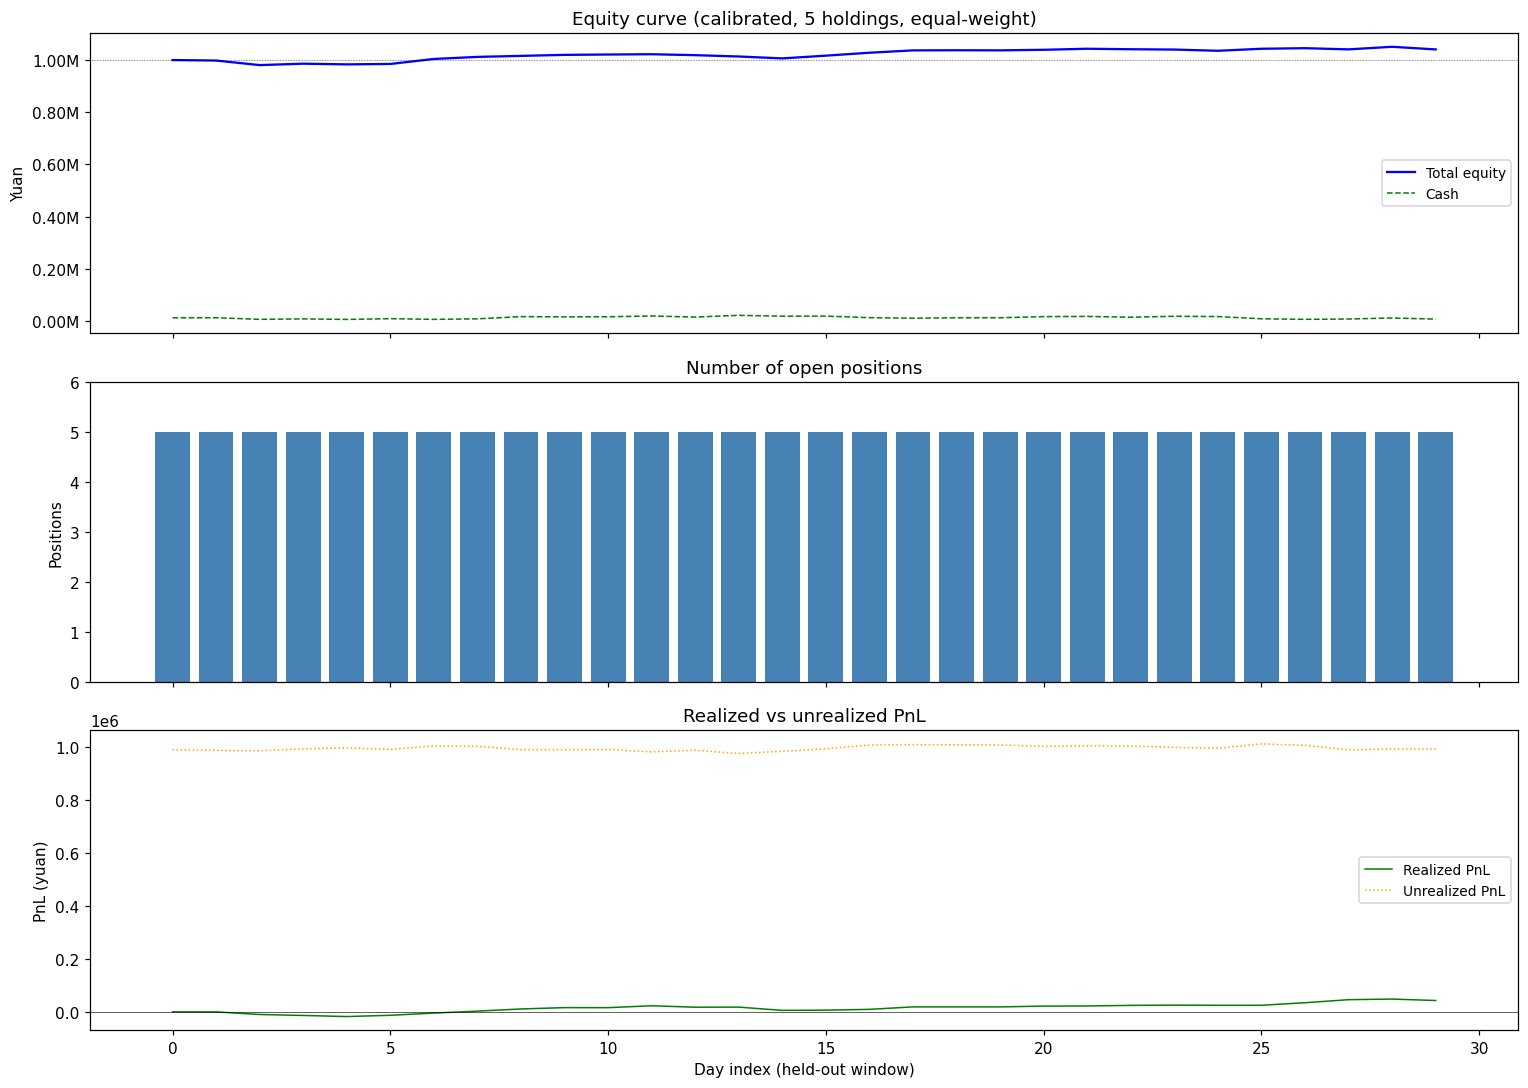

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
x = range(len(held_out))

axes[0].plot(x, equity_hist, linewidth=1.5, color="blue", label="Total equity")
axes[0].plot(x, cash_hist, linewidth=1.0, color="green", linestyle="--", label="Cash")
axes[0].axhline(1_000_000, color="k", linewidth=0.4, linestyle=":")
axes[0].set_ylabel("Yuan")
axes[0].set_title("Equity curve (calibrated, 5 holdings, equal-weight)")
axes[0].legend(fontsize=9)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e6:.2f}M"))

axes[1].bar(x, npos_hist, color="steelblue")
axes[1].set_ylabel("Positions")
axes[1].set_title("Number of open positions")
axes[1].set_ylim(0, max(npos_hist) + 1)

axes[2].plot(x, realized_hist, linewidth=1.0, color="green", label="Realized PnL")
axes[2].plot(x, unrealized_hist, linewidth=1.0, color="orange", linestyle=":", label="Unrealized PnL")
axes[2].axhline(0, color="k", linewidth=0.4)
axes[2].set_ylabel("PnL (yuan)")
axes[2].set_xlabel("Day index (held-out window)")
axes[2].set_title("Realized vs unrealized PnL")
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## 9a. Cross-Sectional Signal Heatmap

Each row is a stock, each column is a held-out date. Color = the model's predicted forward return (ŷ = Σ β·z) on that date. The dashed line marks the **top-5 boundary** each day — stocks above it are long candidates.

What to look for:
- **Persistent dark bands** = stocks the model consistently ranks high (low-turnover alpha).
- **Flickering cells near the boundary** = stocks that keep entering/exiting the top-5 (high turnover, less stable alpha).
- **Color flips** (blue↔red) = the model changes its mind about a stock's direction.

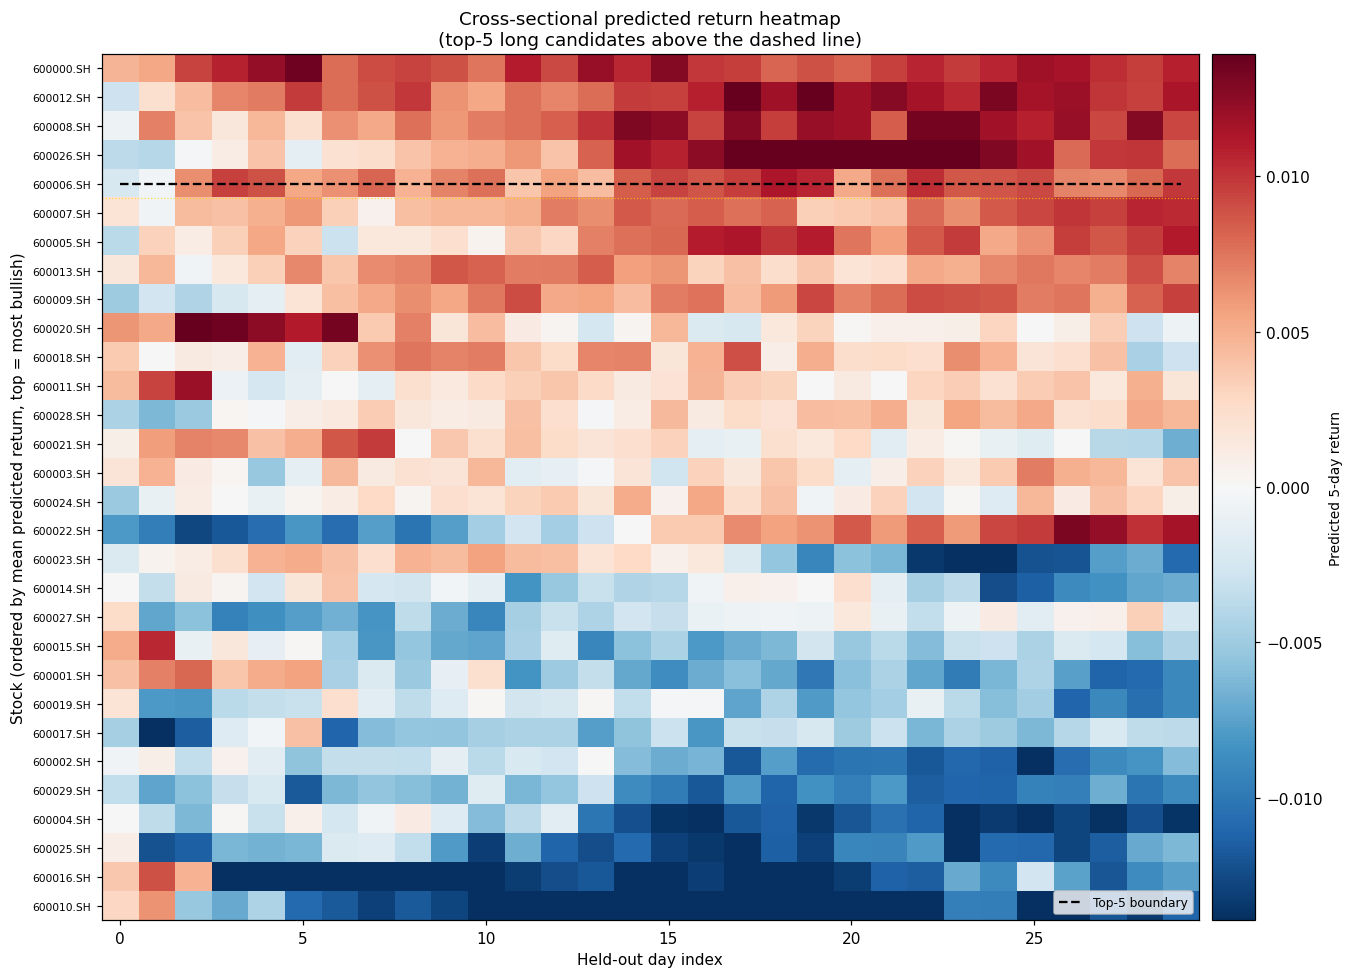

In [16]:
# Order stocks by their average predicted return (most bullish at top)
# so the heatmap reads naturally: top rows = long candidates, bottom = short.
mean_score = np.nanmean(score_matrix, axis=0)
order = np.argsort(-mean_score)  # descending
score_ordered = score_matrix[:, order]
syms_ordered = [all_syms[i] for i in order]

fig, ax = plt.subplots(figsize=(13, 9))
vmax = np.nanpercentile(abs(score_ordered), 95)
im = ax.imshow(score_ordered.T, aspect="auto", cmap="RdBu_r",
               vmin=-vmax, vmax=vmax, interpolation="nearest",
               extent=[-0.5, len(held_out) - 0.5, len(all_syms) - 0.5, -0.5])

# Draw the top-5 boundary: for each date, find the rank of the 5th-highest
# non-NAN score and mark it.
boundary_y = []
for t in range(len(held_out)):
    col = score_ordered[t]
    valid = ~np.isnan(col)
    if valid.sum() < 5:
        boundary_y.append(np.nan)
        continue
    # The 5th-highest valid score's row index (in the ordered frame).
    valid_rows = np.where(valid)[0]
    valid_scores = col[valid_rows]
    # Top-5 are the 5 lowest row indices among valid rows (since ordered desc).
    # Boundary = index of the 5th valid row.
    boundary_y.append(valid_rows[4])  # 0-indexed: rows 0..4 are top-5

ax.plot(range(len(held_out)), boundary_y, "k--", linewidth=1.5, label="Top-5 boundary")
ax.axhline(4.5, color="gold", linewidth=0.8, linestyle=":", alpha=0.7)

ax.set_yticks(range(len(syms_ordered)))
ax.set_yticklabels(syms_ordered, fontsize=7)
ax.set_ylabel("Stock (ordered by mean predicted return, top = most bullish)")
ax.set_xlabel("Held-out day index")
ax.set_title("Cross-sectional predicted return heatmap\n(top-5 long candidates above the dashed line)")
ax.legend(loc="lower right", fontsize=8)
cbar = fig.colorbar(im, ax=ax, pad=0.01)
cbar.set_label("Predicted 5-day return", fontsize=9)
plt.tight_layout()
plt.show()

## 9b. Position Occupancy Heatmap

Same axes as §9a, but color now = **actual portfolio weight** after each day's rebalance. White = not held; colored = held, with color intensity = weight.

Comparing this to §9a reveals the full signal→position chain:
- A cell that is **dark in §9a but white here** = the model liked the stock but it was blocked (cash short, lot rounding, or limit-up).
- A cell that is **light in §9a but colored here** = held over from a previous day (T+1 lock prevents same-day exit), even though the signal faded.
- **Vertical streaks** = stocks held for many consecutive days (low turnover).
- **Isolated cells** = one-day holds (high turnover).

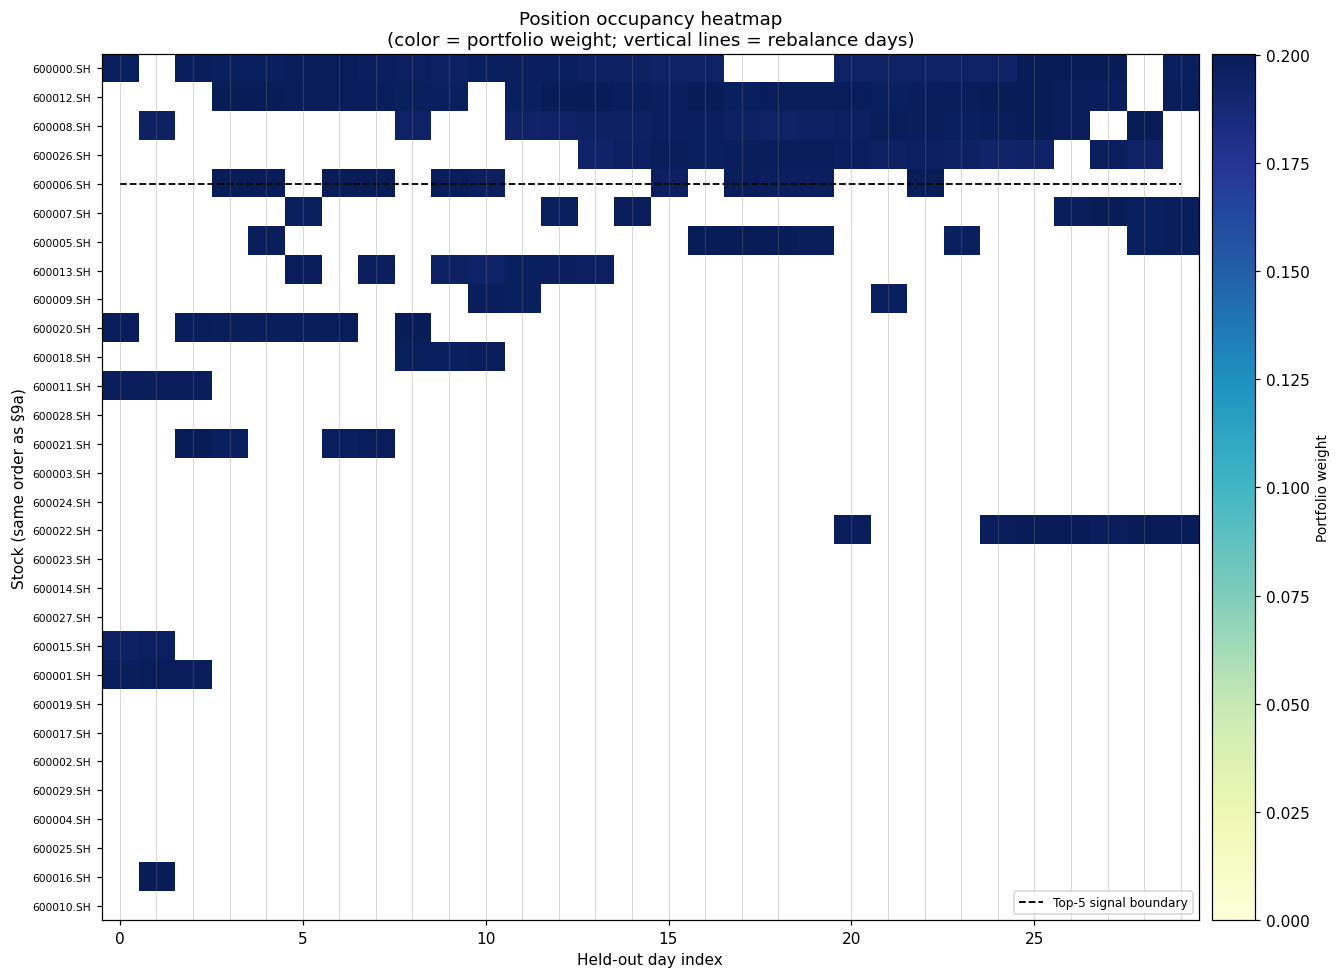

Mean daily weight turnover: 0.5358  (~53.6% of portfolio rebalanced per day)
Stocks ever held: 17 / 30
Median holding days: 7


In [17]:
weight_ordered = weight_matrix[:, order]  # same row order as §9a

fig, ax = plt.subplots(figsize=(13, 9))
# Use a masked array so zero-weight cells render as white/background.
masked = np.ma.masked_where(weight_ordered.T == 0, weight_ordered.T)
cmap = plt.cm.YlGnBu.copy()
cmap.set_bad(color="white")
vmax_w = max(weight_matrix.max(), 1e-6)
im = ax.imshow(masked, aspect="auto", cmap=cmap, vmin=0, vmax=vmax_w,
               interpolation="nearest",
               extent=[-0.5, len(held_out) - 0.5, len(all_syms) - 0.5, -0.5])

# Overlay the top-5 boundary from §9a for direct comparison.
ax.plot(range(len(held_out)), boundary_y, "k--", linewidth=1.2,
        label="Top-5 signal boundary")

# Mark rebalance days (days with any trade) with vertical grid lines.
rebal_days = [t for t, d in enumerate(held_out)
              if any(tr.date == d for tr in pm.trades)]
for t in rebal_days:
    ax.axvline(t, color="gray", linewidth=0.4, alpha=0.5)

ax.set_yticks(range(len(syms_ordered)))
ax.set_yticklabels(syms_ordered, fontsize=7)
ax.set_ylabel("Stock (same order as §9a)")
ax.set_xlabel("Held-out day index")
ax.set_title("Position occupancy heatmap\n(color = portfolio weight; vertical lines = rebalance days)")
ax.legend(loc="lower right", fontsize=8)
cbar = fig.colorbar(im, ax=ax, pad=0.01)
cbar.set_label("Portfolio weight", fontsize=9)
plt.tight_layout()
plt.show()

# Quantify turnover: mean day-to-day weight change (excludes entry/exit edges).
turnover = np.abs(np.diff(weight_matrix, axis=0)).sum(axis=1).mean()
print(f"Mean daily weight turnover: {turnover:.4f}  "
      f"(~{turnover*100:.1f}% of portfolio rebalanced per day)")
print(f"Stocks ever held: {int((weight_matrix > 0).any(axis=0).sum())} / {len(all_syms)}")
print(f"Median holding days: "
      f"{np.median([(weight_matrix[:, i] > 0).sum() for i in range(len(all_syms)) if (weight_matrix[:, i] > 0).any()]):.0f}")

## 9c. Turnover – How Much the Portfolio Shuffles

Two views on the cost of maintaining a signal:

### Factor turnover (profiler side)
Average day-to-day rank-change of a factor's cross-sectional sort.
High turnover = signal is expensive to trade (daily churn); low turnover = cheap, persistent alpha.

Measured as `mean(|Δrank|) / (n_stocks - 1)` across consecutive date pairs.

### Portfolio turnover (backtest side)
How much of the portfolio's total allocation is bought/sold each day.

Measured as `daily_turnover = Σ|weight[t] - weight[t-1]|` — the sum of absolute
weight changes across all held stocks.

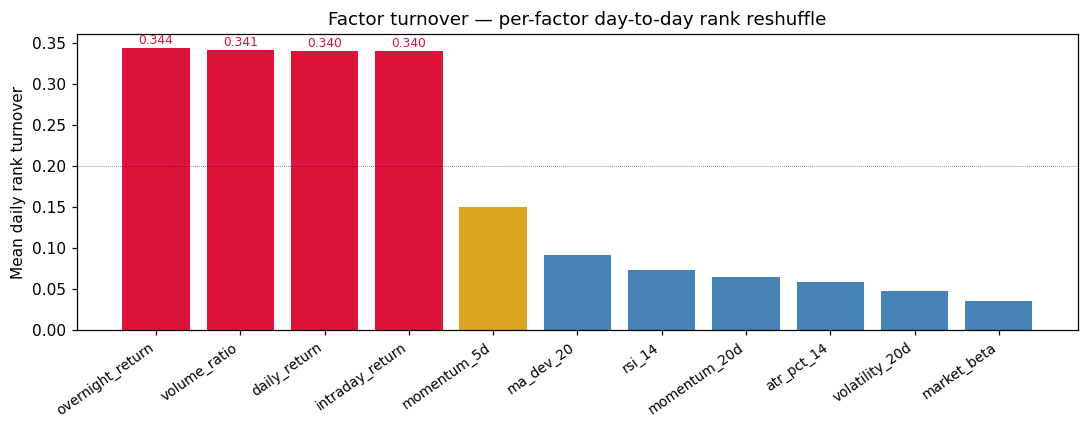

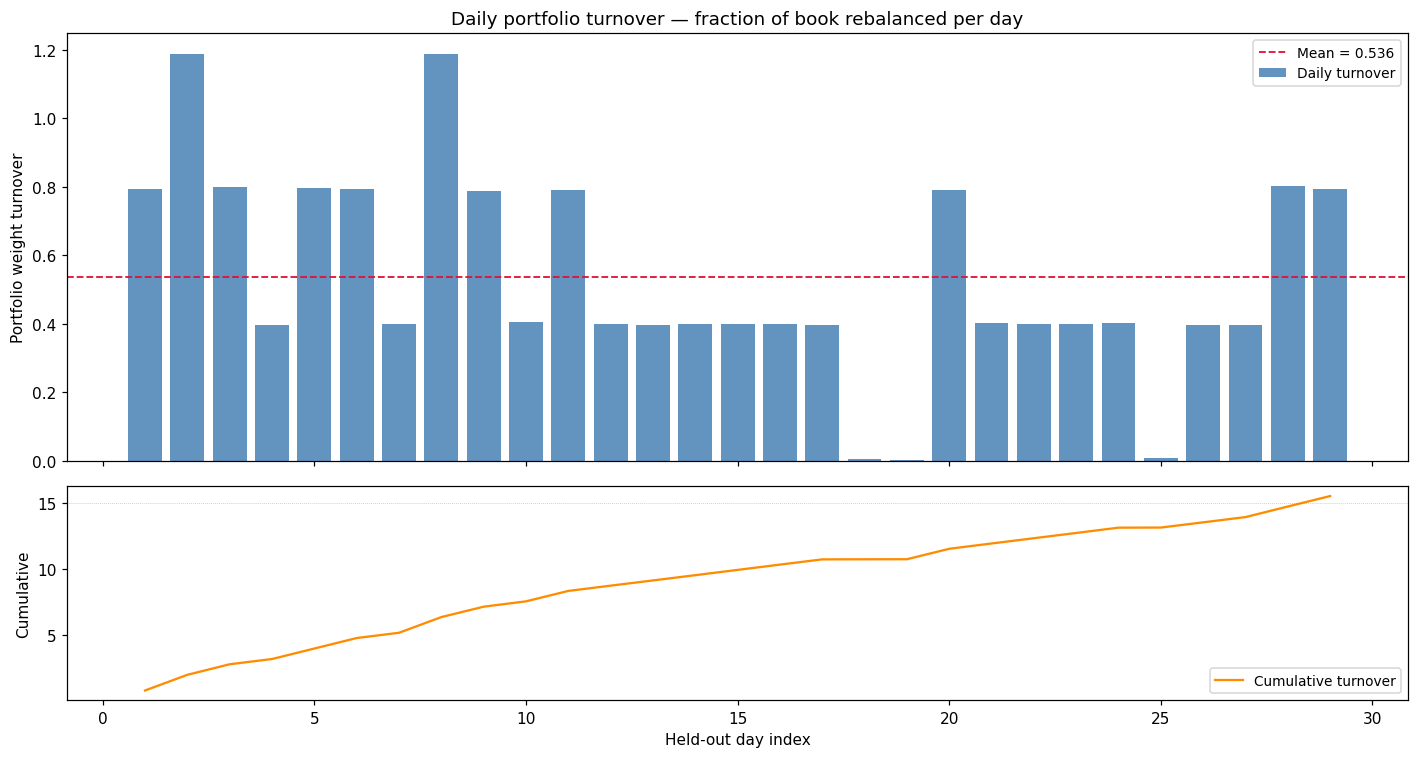

Daily turnover: mean = 0.5358, median = 0.4007, max = 1.1894
Cumulative turnover over 29 days: 15.537 (0.5x the universe size)


In [18]:
# A) Factor-level turnover comparison (bar chart)
# Re-use the sorted factor profiles from the profiler (model_profile).
factor_turns = {fp.name: fp.turnover for fp in model_profile.factor_profiles}
sorted_turns = sorted(factor_turns.items(), key=lambda x: -x[1])
names = [n for n, _ in sorted_turns]
vals = [v for _, v in sorted_turns]

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["crimson" if v > 0.25 else "goldenrod" if v > 0.10 else "steelblue"
          for v in vals]
bars = ax.bar(names, vals, color=colors)
ax.set_ylabel("Mean daily rank turnover")
ax.set_title("Factor turnover — per-factor day-to-day rank reshuffle")
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=35, ha="right", fontsize=9)
ax.axhline(0.20, color="k", linewidth=0.5, linestyle=":", alpha=0.7)
# Annotate the two highest-turnover factors.
for bar, v in zip(bars, vals):
    if v > 0.20:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f"{v:.3f}", ha="center", fontsize=8, color="crimson")
plt.tight_layout()
plt.show()

# B) Daily portfolio turnover (time-series bar chart)
# weight_matrix is from §9. Already computed there.
daily_turnover = np.abs(np.diff(weight_matrix, axis=0)).sum(axis=1)

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

x = range(1, len(daily_turnover) + 1)  # day 1..N (change is between t and t-1)

axes[0].bar(x, daily_turnover, color="steelblue", alpha=0.85, label="Daily turnover")
axes[0].axhline(np.mean(daily_turnover), color="crimson", linewidth=1.2,
                linestyle="--", label=f"Mean = {np.mean(daily_turnover):.3f}")
axes[0].set_ylabel("Portfolio weight turnover")
axes[0].set_title("Daily portfolio turnover — fraction of book rebalanced per day")
axes[0].legend(fontsize=9)

# Cumulative turnover: moving sum of daily turnover shows total churn.
cum = np.cumsum(daily_turnover)
axes[1].plot(x, cum, color="darkorange", linewidth=1.5, label="Cumulative turnover")
axes[1].set_ylabel("Cumulative")
axes[1].set_xlabel("Held-out day index")
axes[1].legend(fontsize=9)
axes[1].axhline(len(all_syms) * 0.5, color="gray", linewidth=0.5, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

print(f"Daily turnover: mean = {np.mean(daily_turnover):.4f}, "
      f"median = {np.median(daily_turnover):.4f}, "
      f"max = {np.max(daily_turnover):.4f}")
print(f"Cumulative turnover over {len(daily_turnover)} days: {cum[-1]:.3f} "
      f"({cum[-1]/len(all_syms):.1f}x the universe size)")

## 9d. Style Exposure Analysis

How much of the portfolio's return comes from **market beta** vs. other style
factors vs. pure stock selection (α)?

We decompose the portfolio's daily return via time-series regression:

    r_portfolio[t] = α + β_market × r_market[t] + β_size × r_size[t] + ε[t]

This tells us: when the market is up 1%, does our book go up 0.5% (defensive)
or 1.5% (aggressive)? Are we accidentally long small-caps?

In [19]:
# 1. Portfolio daily returns from the equity series
portfolio_return = np.array(equity_hist[1:]) / np.array(equity_hist[:-1]) - 1
# Align market return to the same length (returns are between day t and t+1)
mkt_return = np.array([bars_full[d][uni_full.symbols[0]].market_return
                       for d in held_out[1:]])  # t+1 market return matches portfolio_return[t]

# 2. Per-stock daily returns for style-return construction
all_stock_rets = np.zeros((len(held_out), len(uni_full.symbols)))
for t, d in enumerate(held_out):
    for j, s in enumerate(uni_full.symbols):
        b = bars_full[d][s]
        if b.prev_close > 0:
            all_stock_rets[t, j] = (b.close - b.prev_close) / b.prev_close

# 3. Construct a "high-beta vs. low-beta" style return from the cross-section.
#    Sort by predicted return (score_matrix from §9) as a proxy for beta rank.
beta_style_ret = np.zeros(len(held_out))
for t in range(len(held_out)):
    order = np.argsort(score_matrix[t])
    n = len(order)
    n_bucket = max(n // 3, 1)
    # Low-prediction (low-beta) stocks vs. high-prediction (high-beta) stocks
    lo_ret = np.mean(all_stock_rets[t, order[:n_bucket]])
    hi_ret = np.mean(all_stock_rets[t, order[-n_bucket:]])
    beta_style_ret[t] = hi_ret - lo_ret

# Use t+1 style returns (since portfolio return is based on t+1 bar)
beta_style_aligned = beta_style_ret[1:]  # same length as portfolio_return

# 4. Time-series regression
X = np.column_stack([np.ones_like(mkt_return), mkt_return, beta_style_aligned])
y = portfolio_return
coeffs = np.linalg.lstsq(X, y, rcond=None)[0]
alpha_exposure = coeffs[0]
beta_mkt_exposure = coeffs[1]
beta_beta_exposure = coeffs[2]
y_pred = X @ coeffs
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2_exposure = 1.0 - ss_res / ss_tot if ss_tot > 1e-12 else 0.0

print("=== Style exposure (time-series regression) ===")
print(f"  N (trading days):                            {len(portfolio_return)}")
print(f"  alpha (daily pure stock selection):          {alpha_exposure:+.5f}  ({alpha_exposure*252*100:+.2f}% ann)")
print(f"  beta_market (sensitivity to market returns): {beta_mkt_exposure:+.3f}")
print(f"  beta_style  (sensitivity to hi/lo spread):   {beta_beta_exposure:+.3f}")
print(f"  R² (frac of portfolio variance explained):   {r2_exposure:.4f}")
print()
print("Interpretation:")
if abs(beta_mkt_exposure) < 0.3:
    print("  → Market-neutral: portfolio is largely immune to market swings.")
elif beta_mkt_exposure > 0.7:
    print("  → Market-beta heavy: portfolio rides the market; up in rallies, down in selloffs.")
else:
    print(f"  → Mild market tilt (beta_mkt={beta_mkt_exposure:.3f}) — partial exposure.")
if abs(alpha_exposure) > 0.001:
    print(f"  → α positive ({alpha_exposure*252*100:.1f}% ann): the stock-selection layer is adding value above styles.")
else:
    print("  → α near zero: almost all return can be explained by the style factors.")

=== Style exposure (time-series regression) ===
  N (trading days):                            29
  alpha (daily pure stock selection):          +0.00195  (+49.16% ann)
  beta_market (sensitivity to market returns): +1.318
  beta_style  (sensitivity to hi/lo spread):   +0.189
  R² (frac of portfolio variance explained):   0.6789

Interpretation:
  → Market-beta heavy: portfolio rides the market; up in rallies, down in selloffs.
  → α positive (49.2% ann): the stock-selection layer is adding value above styles.


## 9e. Market-Neutralisation — Before vs. After

What happens when we strip the market-beta component from every factor *before*
z-scoring (via ``standardize_cross_section(..., neutralize=["market_beta"])``)?

We run the same pipeline twice — once with neutralization, once without — and
compare the calibration, backtest equity, and style exposures.

In [20]:
# ── Calibration WITH neutralization ──
off_engine_neut = TradingEngine(neutralize=["market_beta"])
cal_neut = FactorCalibrator(horizon=5, alpha=1.0, min_samples=50, min_dates=10)
for d in split:
    cs = off_engine_neut.build_cross_section(d, bars_full[d])
    cal_neut.collect(d, cs, bars_full)
result_neut = cal_neut.fit()

live_neut = TradingEngine(calibration=result_neut, neutralize=["market_beta"])
pm_neut = PortfolioManager(
    capital=1_000_000.0, n_holdings=5, weighting="equal",
    aggregator=SignalAggregator(calibration=result_neut),
)

eq_neut, score_neut, weight_neut = [], [], []
for t, d in enumerate(held_out):
    sigs = live_neut.on_cross_section(d, bars_full[d])
    pm_neut.decide(d, bars_full[d], sigs)
    eq = pm_neut.portfolio.mark_to_market(bars_full[d])
    eq_neut.append(eq)

# ── Compare calibration — which betas changed? ──
print("=== Beta comparison — raw vs. neutralised ===")
print(f"  {'Factor':<16} {'raw beta':>12} {'neut beta':>12} {'delta':>10}")
print(f"  {'-'*16} {'-'*12} {'-'*12} {'-'*10}")
for name in result.factor_names:
    if name == "market_beta":
        continue  # market_beta isn't residualised against itself
    b_raw = result.betas.get(name, 0.0)
    b_neut = result_neut.betas.get(name, 0.0)
    delta = b_neut - b_raw
    print(f"  {name:<16} {b_raw:>12.5f} {b_neut:>12.5f} {delta:>+10.5f}")

# ── Equity comparison ──
print(f"\n=== Backtest comparison (30 held-out days) ===")
print(f"  Without neutralisation:  final equity = {equity_hist[-1]:,.0f}  "
      f"return = {(equity_hist[-1]/1e6-1)*100:+.2f}%  trades = {len(pm.trades)}")
print(f"  With neutralisation:     final equity = {eq_neut[-1]:,.0f}  "
      f"return = {(eq_neut[-1]/1e6-1)*100:+.2f}%  trades = {len(pm_neut.trades)}")
print(f"  Equity correlation:      {np.corrcoef(equity_hist, eq_neut)[0,1]:.4f}")

# ── Style exposure: re-run for the neutralised portfolio ──
eq_neut_arr = np.array(eq_neut)
port_ret_neut = eq_neut_arr[1:] / eq_neut_arr[:-1] - 1
X_neut_reg = np.column_stack([np.ones_like(mkt_return), mkt_return, beta_style_aligned])
coeff_neut = np.linalg.lstsq(X_neut_reg, port_ret_neut, rcond=None)[0]

print(f"\n=== Style exposure — neutralised vs raw ===")
print(f"  {'Metric':<20} {'raw':>10} {'neutralised':>12}")
print(f"  {'-'*20} {'-'*10} {'-'*12}")
print(f"  {'alpha (daily)':<20} {alpha_exposure:>+10.5f} {coeff_neut[0]:>+12.5f}")
print(f"  {'beta_market':<20} {beta_mkt_exposure:>+10.3f} {coeff_neut[1]:>+12.3f}")
print(f"  {'beta_style':<20} {beta_beta_exposure:>+10.3f} {coeff_neut[2]:>+12.3f}")

=== Beta comparison — raw vs. neutralised ===
  Factor               raw beta    neut beta      delta
  ---------------- ------------ ------------ ----------
  daily_return         -0.00080     -0.00082   -0.00003
  overnight_return     -0.00022     -0.00027   -0.00005
  intraday_return      -0.00068     -0.00069   -0.00001
  momentum_5d          -0.00238     -0.00230   +0.00008
  momentum_20d         -0.00097     -0.00101   -0.00003
  ma_dev_20             0.00169      0.00181   +0.00012
  volatility_20d       -0.00464     -0.00806   -0.00342
  volume_ratio          0.00073      0.00207   +0.00134
  rsi_14                0.00209      0.00312   +0.00103
  atr_pct_14           -0.00292     -0.00242   +0.00050

=== Backtest comparison (30 held-out days) ===
  Without neutralisation:  final equity = 1,040,433  return = +4.04%  trades = 107
  With neutralisation:     final equity = 1,038,363  return = +3.84%  trades = 136
  Equity correlation:      0.9772

=== Style exposure — neutralised 

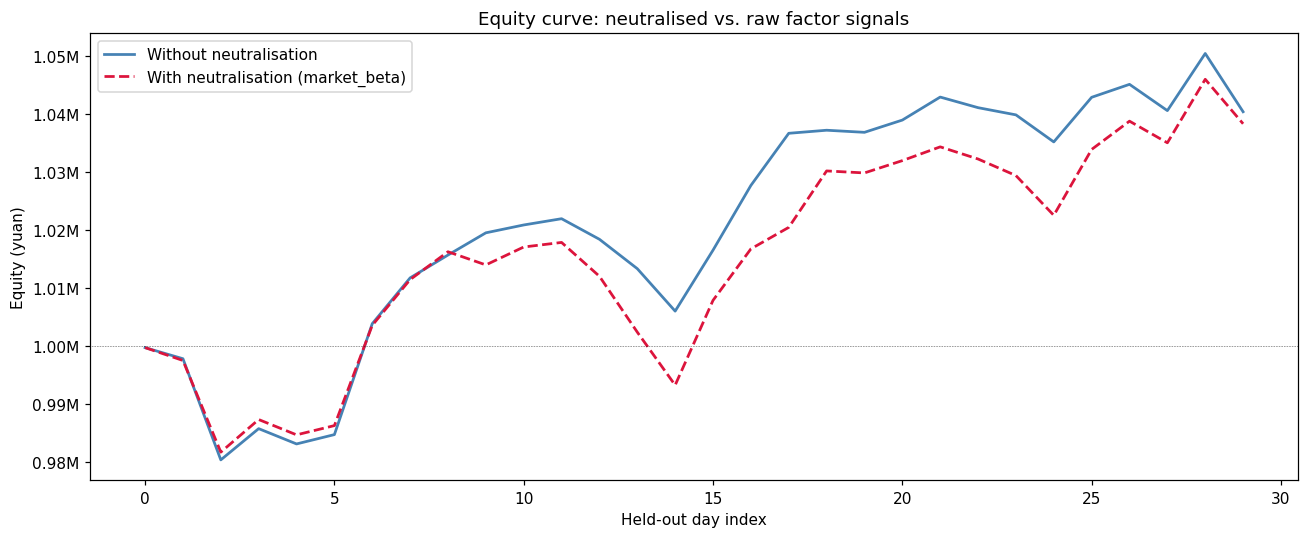

In [21]:
fig, ax = plt.subplots(figsize=(12, 5))
x = range(len(held_out))
ax.plot(x, equity_hist, linewidth=1.8, color="steelblue", label="Without neutralisation")
ax.plot(x, eq_neut, linewidth=1.8, color="crimson", linestyle="--", label="With neutralisation (market_beta)")
ax.axhline(1_000_000, color="k", linewidth=0.4, linestyle=":")
ax.set_ylabel("Equity (yuan)")
ax.set_xlabel("Held-out day index")
ax.set_title("Equity curve: neutralised vs. raw factor signals")
ax.legend(fontsize=10)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e6:.2f}M"))
plt.tight_layout()
plt.show()

## 9f. Portfolio Hedge — Simulated Short Futures

What if we had shorted index futures to cancel the portfolio's market exposure
in real time?  ``HedgeManager`` models a dynamic short position:

  * Rolling OLS beta from the last 20 days of portfolio & market returns.
  * Short lots proportional to β × equity ÷ notional‑per‑lot.
  * Daily mark‑to‑market settlement.
  * Annualised roll‑cost drag (6 %).

**An important real‑world constraint**: CFFEX futures have a 200× multiplier,
so one IM lot = index × 200 yuan.  With a 1 M yuan portfolio at index ≈ 5 500,
one lot costs ~1.1 M — the book is *too small* to open even one whole contract.
Below we show the theoretical hedge using a hypothetical **100× mini contract**
to demonstrate the mechanics.

In [22]:
from alftrade.hedge import HedgeManager, FuturesContract, compute_hedged_equity

# Reconstruct index level from cumulative market returns.
index_start = 5500.0
index_level = np.zeros(len(held_out))
index_level[0] = index_start
cum = 1.0
for t in range(1, len(held_out)):
    cum *= (1.0 + bars_full[held_out[t]][uni_full.symbols[0]].market_return)
    index_level[t] = index_start * cum

# Run HedgeManager (actual — whole lots, 200x multiplier)
hm = HedgeManager(
    contract=FuturesContract("IM", multiplier=200.0),
    beta_window=20,
    min_beta_t=0.0,
    max_leverage=1.5,
)

hedge_pnl_hist, lots_hist, beta_hist = [], [], []
for t, d in enumerate(held_out):
    eq = equity_hist[t] if t < len(equity_hist) else equity_hist[-1]
    port_ret = portfolio_return[t] if t < len(portfolio_return) else 0.0
    mkt_ret = bars_full[d][uni_full.symbols[0]].market_return
    pnl, lots, beta = hm.step(d, eq, port_ret, mkt_ret, index_level[t])
    hedge_pnl_hist.append(pnl)
    lots_hist.append(lots)
    beta_hist.append(beta)

# Hedge with 100x multiplier so at least 1 lot can open.
hm_mini = HedgeManager(
    contract=FuturesContract("IM-mini", multiplier=100.0),
    beta_window=20,
    min_beta_t=0.0,
    max_leverage=1.5,
)
hedge_pnl_mini, lots_mini, _ = [], [], []
for t, d in enumerate(held_out):
    eq = equity_hist[t] if t < len(equity_hist) else equity_hist[-1]
    port_ret = portfolio_return[t] if t < len(portfolio_return) else 0.0
    mkt_ret = bars_full[d][uni_full.symbols[0]].market_return
    pnl, lots, beta = hm_mini.step(d, eq, port_ret, mkt_ret, index_level[t])
    hedge_pnl_mini.append(pnl)
    lots_mini.append(lots)

hedged_mini = compute_hedged_equity(equity_hist, [], hedge_pnl_mini)

print(f"=== Hedge summary ===")
print(f"  200x contract (actual):  max lots = {max(lots_hist)}")
print(f"    → Portfolio too small: 1 lot = {5500*0.2:.0f}K yuan, notional too high for {1e6/1e6:.1f}M book.")
print(f"  100x contract (hypothetical mini):  max lots = {max(lots_mini)}")
print(f"    → Cumulative hedge PnL:  {hm_mini.cumulative_pnl:+,.0f} yuan")
print(f"    → Raw final equity:       {equity_hist[-1]:,.0f}")
print(f"    → Hedged final equity:    {hedged_mini[-1]:,.0f}")
print(f"    → Hedge impact:           {hedged_mini[-1] - equity_hist[-1]:+,.0f} yuan")
print(f"  Mean |beta|:               {np.mean(np.abs(beta_hist)):.3f}")

=== Hedge summary ===
  200x contract (actual):  max lots = 0
    → Portfolio too small: 1 lot = 1100K yuan, notional too high for 1.0M book.
  100x contract (hypothetical mini):  max lots = 1
    → Cumulative hedge PnL:  +9,872 yuan
    → Raw final equity:       1,040,433
    → Hedged final equity:    1,051,998
    → Hedge impact:           +11,565 yuan
  Mean |beta|:               0.601


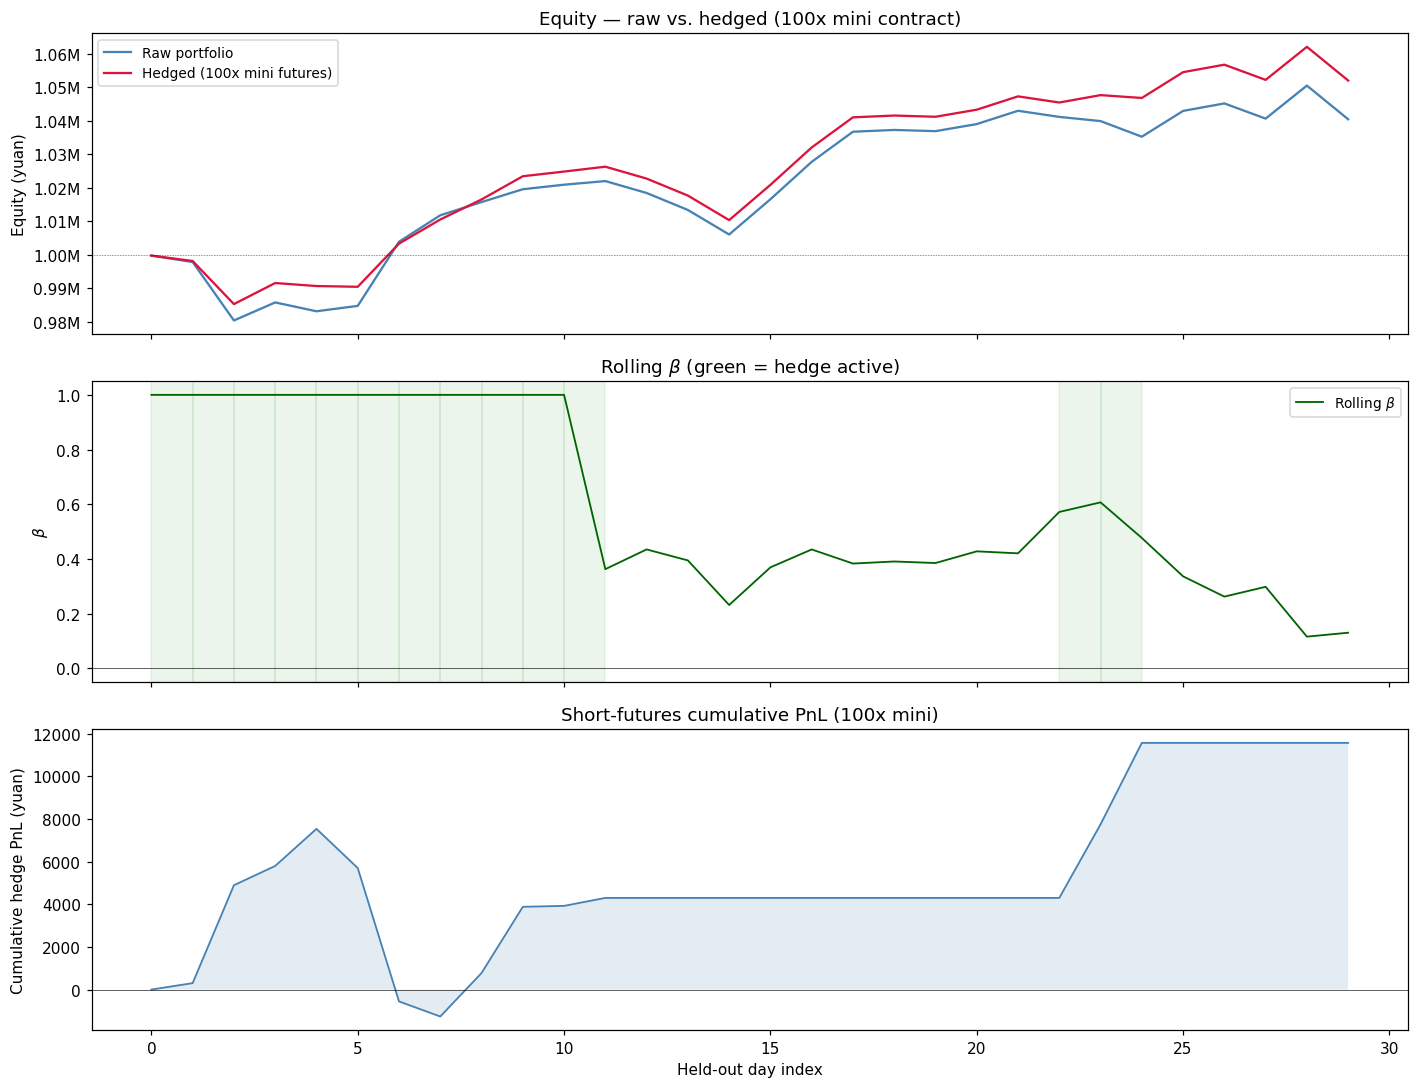

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

axes[0].plot(range(len(held_out)), equity_hist, linewidth=1.5, color="steelblue",
             label="Raw portfolio")
axes[0].plot(range(len(held_out)), hedged_mini, linewidth=1.5, color="crimson",
             label="Hedged (100x mini futures)")
axes[0].axhline(1_000_000, color="k", linewidth=0.4, linestyle=":")
axes[0].set_ylabel("Equity (yuan)")
axes[0].set_title("Equity — raw vs. hedged (100x mini contract)")
axes[0].legend(fontsize=9)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e6:.2f}M"))

axes[1].plot(range(len(held_out)), beta_hist, linewidth=1.2, color="darkgreen",
             label="Rolling $\\beta$")
axes[1].axhline(0, color="k", linewidth=0.4)
hedge_on = np.array([l > 0 for l in lots_mini])
for i in range(len(hedge_on) - 1):
    if hedge_on[i]:
        axes[1].axvspan(i, i + 1, color="green", alpha=0.08)
axes[1].set_ylabel("$\\beta$")
axes[1].set_title("Rolling $\\beta$ (green = hedge active)")
axes[1].legend(fontsize=9)

cum_pnl = np.cumsum(hedge_pnl_mini)
axes[2].fill_between(range(len(held_out)), cum_pnl, 0,
                     facecolor="steelblue", alpha=0.15)
axes[2].plot(range(len(held_out)), cum_pnl, linewidth=1.2, color="steelblue")
axes[2].axhline(0, color="k", linewidth=0.4)
axes[2].set_ylabel("Cumulative hedge PnL (yuan)")
axes[2].set_xlabel("Held-out day index")
axes[2].set_title("Short-futures cumulative PnL (100x mini)")

plt.tight_layout()
plt.show()

### Trade-by-trade breakdown

Each trade shows the A-share cost breakdown (commission + stamp duty on sells).

In [24]:
print(f"{'#':>3}  {'Date':>10}  {'Symbol':<12}  {'Dir':<8}  {'Qty':>8}  {'Price':>8}  {'Cost':>8}  {'Reason':<14}")
print("-" * 88)
for i, t in enumerate(pm.trades[:25]):
    print(f"{i+1:>3}  {t.date:>10}  {t.symbol:<12}  {t.direction:<8}  "
          f"{t.quantity:>+8.0f}  {t.price:>8.2f}  {t.cost:>8.2f}  {t.reason:<14}")
if len(pm.trades) > 25:
    print(f"  ... and {len(pm.trades) - 25} more trades")

  #        Date  Symbol        Dir            Qty     Price      Cost  Reason        
----------------------------------------------------------------------------------------
  1    20200321  600020.SH     OPEN         +9000     22.12     53.75  REBALANCE     
  2    20200321  600015.SH     OPEN         +2900     67.24     52.65  REBALANCE     
  3    20200321  600000.SH     OPEN         +2800     70.36     53.19  REBALANCE     
  4    20200321  600011.SH     OPEN         +4400     45.11     53.59  REBALANCE     
  5    20200321  600001.SH     OPEN         +9300     21.31     53.50  REBALANCE     
  6    20200322  600020.SH     CLOSE        -9000     22.39    255.97  REBALANCE     
  7    20200322  600000.SH     CLOSE        -2800     69.64    247.63  REBALANCE     
  8    20200322  600016.SH     OPEN        +18500     10.77     53.78  REBALANCE     
  9    20200322  600001.SH     INCREASE      +100     21.12      5.04  REBALANCE     
 10    20200322  600008.SH     OPEN         +2300  

---

## 10. Risk Management — A-share Pre-trade & Post-bar Controls

The `RiskManager` sits between the `PortfolioManager` and `Portfolio.apply_trade`. It enforces both **A-share structural rules** (T+1, price-limit lock, board lot, concentration) and **portfolio-level monitors** (stop-loss, drawdown, daily-loss limit).

### Pre-trade rules

| Rule | Config field | Behaviour |
|------|-------------|-----------|
| T+1 settlement | `enforce_t1` | Shrinks sells to `available_qty` (= qty − t1_locked) |
| Price-limit lock | `reject_limit_locked` | Reject buys at limit-up, sells at limit-down |
| Board lot | `enforce_lot` | Round buys down to multiples of 100 shares |
| Concentration | `max_weight_per_name` | Shrink buys so post-trade weight ≤ cap |
| Notional cap | `max_notional_per_trade` | Shrink any trade exceeding yuan limit |
| Order frequency | `max_trades_per_day` | Reject once per-day cap hit |
| Circuit breaker | `halted` flag | Reject new OPENs when halted (closes still allowed) |
| Suspension | `reject_suspended` | Reject all trades on halted symbols |

### Post-bar monitors

| Monitor | Config field | Trigger |
|---------|-------------|---------|
| Stop loss | `stop_loss_pct` | Per-position unrealized loss > pct of cost |
| Take profit | `take_profit_pct` | Per-position unrealized profit > pct of cost |
| Max drawdown | `max_drawdown_pct` | Equity drops from peak by pct → halt + liquidate |
| Daily loss limit | `daily_loss_limit_pct` | Daily realized loss > pct of capital → halt + liquidate |

In [25]:
# Configure A-share risk rules
risk_cfg = RiskConfig(
    enforce_t1=True,
    enforce_lot=True,
    reject_limit_locked=True,
    reject_suspended=True,
    max_weight_per_name=0.25,        # max 25% in any single stock
    max_notional_per_trade=200_000,  # max 200k yuan per trade
    max_trades_per_day=20,
    stop_loss_pct=0.08,              # cut losers at -8%
    take_profit_pct=None,            # let winners run
    max_drawdown_pct=0.15,           # halt at -15% from peak
    daily_loss_limit_pct=0.03,       # halt at -3% daily realized loss
)

pm_risk = PortfolioManager(
    capital=1_000_000.0,
    n_holdings=5,
    weighting="equal",
    aggregator=SignalAggregator(calibration=result),
    risk_manager=RiskManager(risk_cfg, initial_capital=1_000_000.0),
)
live_engine_risk = TradingEngine(calibration=result)

equity_risk, npos_risk = [], []
for d in held_out:
    sigs = live_engine_risk.on_cross_section(d, bars_full[d])
    pm_risk.decide(d, bars_full[d], sigs)
    equity_risk.append(pm_risk.portfolio.mark_to_market(bars_full[d]))
    npos_risk.append(sum(1 for p in pm_risk.portfolio.positions.values() if p.quantity > 0))

print(f"With risk:    final equity = {equity_risk[-1]:,.0f}  "
      f"return = {(equity_risk[-1]/1e6-1)*100:+.2f}%  trades = {len(pm_risk.trades)}")
print(f"Without risk: final equity = {equity_hist[-1]:,.0f}  "
      f"return = {(equity_hist[-1]/1e6-1)*100:+.2f}%  trades = {len(pm.trades)}")

With risk:    final equity = 1,040,548  return = +4.05%  trades = 125
Without risk: final equity = 1,040,433  return = +4.04%  trades = 107


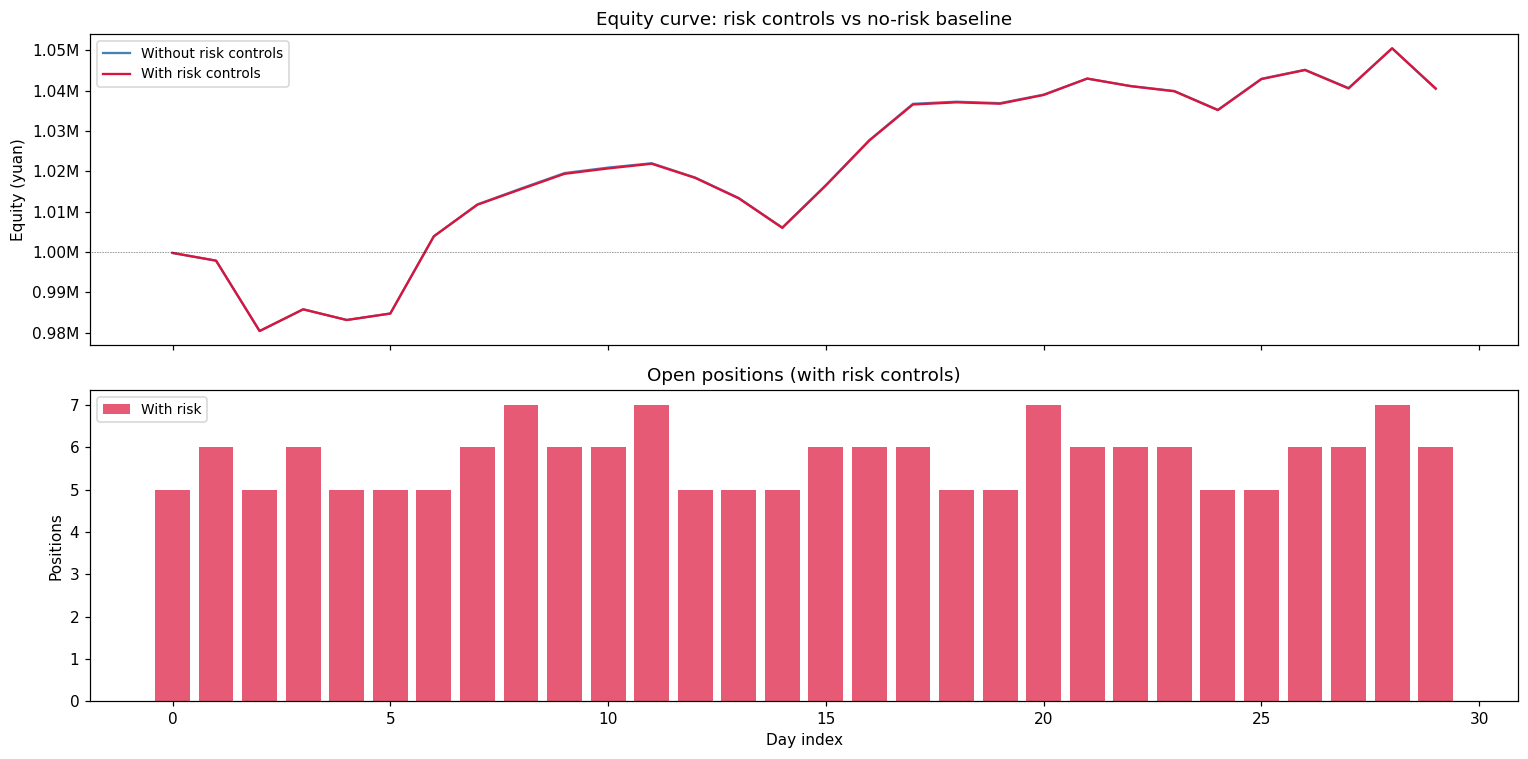

In [26]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
x = range(len(held_out))

axes[0].plot(x, equity_hist, linewidth=1.5, color="steelblue", label="Without risk controls")
axes[0].plot(x, equity_risk, linewidth=1.5, color="crimson", label="With risk controls")
axes[0].axhline(1_000_000, color="k", linewidth=0.4, linestyle=":")
axes[0].set_ylabel("Equity (yuan)")
axes[0].set_title("Equity curve: risk controls vs no-risk baseline")
axes[0].legend(fontsize=9)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e6:.2f}M"))

axes[1].bar(x, npos_risk, color="crimson", alpha=0.7, label="With risk")
axes[1].set_ylabel("Positions")
axes[1].set_xlabel("Day index")
axes[1].set_title("Open positions (with risk controls)")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

### Risk-triggered trades

Trades with `STOP_LOSS`, `TAKE_PROFIT`, `MAX_DRAWDOWN`, or `DAILY_LOSS_LIMIT` reasons are forced by the post-bar monitor, not by signals.

In [27]:
risk_trades = [t for t in pm_risk.trades
               if t.reason in ("STOP_LOSS", "TAKE_PROFIT", "MAX_DRAWDOWN", "DAILY_LOSS_LIMIT")]
print(f"Risk-triggered trades: {len(risk_trades)}")
for t in risk_trades[:10]:
    print(f"  {t}")
if pm_risk.risk.halted:
    print(f"\n⚠ System halted (drawdown or daily-loss limit breached)")

Risk-triggered trades: 0


### 10a. Circuit breaker demonstration

With a very tight drawdown limit, the system halts early and blocks all new opens for the rest of the run.

In [28]:
tight_cfg = RiskConfig(
    max_weight_per_name=0.25,
    stop_loss_pct=0.05,
    max_drawdown_pct=0.03,        # halt at just -3% from peak
    daily_loss_limit_pct=0.02,
    max_notional_per_trade=None,
    max_trades_per_day=None,
)

pm_tight = PortfolioManager(
    capital=1_000_000.0,
    n_holdings=5,
    aggregator=SignalAggregator(calibration=result),
    risk_manager=RiskManager(tight_cfg, initial_capital=1_000_000.0),
)
eng_tight = TradingEngine(calibration=result)

halt_date = None
for d in held_out:
    pm_tight.decide(d, bars_full[d], eng_tight.on_cross_section(d, bars_full[d]))
    if pm_tight.risk.halted and halt_date is None:
        halt_date = d
        eq = pm_tight.portfolio.mark_to_market(bars_full[d])
        print(f"Halted on {d} at equity {eq:,.0f} "
              f"(return {(eq/1e6-1)*100:+.2f}%)")
        break

if halt_date is None:
    print("System did not halt with the tight config on this run.")

System did not halt with the tight config on this run.


### 10b. Verifying A-share structural constraints

After a full run, verify that the portfolio never violated T+1, never went short, and all buys were in 100-share lots.

In [29]:
# Re-run the full pipeline and check all A-share constraints
pm_check = PortfolioManager(
    capital=1_000_000.0,
    n_holdings=5,
    aggregator=SignalAggregator(calibration=result),
)
eng_check = TradingEngine(calibration=result)

for d in held_out:
    pm_check.decide(d, bars_full[d], eng_check.on_cross_section(d, bars_full[d]))

# 1. Long-only: no position ever went negative
any_short = any(p.quantity < 0 for p in pm_check.portfolio.positions.values())

# 2. Board lot: every buy is a multiple of 100
bad_lots = [t for t in pm_check.trades if t.quantity > 0 and int(t.quantity) % 100 != 0]

# 3. T+1: no symbol was bought and sold on the same date
from collections import defaultdict
day_sym = defaultdict(set)
for t in pm_check.trades:
    if t.quantity > 0:
        day_sym[(t.date, t.symbol)].add("B")
    elif t.quantity < 0:
        day_sym[(t.date, t.symbol)].add("S")
t1_violations = [k for k, v in day_sym.items() if v == {"B", "S"}]

# 4. No trades on suspended or limit-locked bars
bad_limit = []
for t in pm_check.trades:
    bar = bars_full[t.date].get(t.symbol)
    if bar is None:
        continue
    if t.quantity > 0 and bar.is_limit_up:
        bad_limit.append((t, "buy at limit_up"))
    if t.quantity < 0 and bar.is_limit_down:
        bad_limit.append((t, "sell at limit_down"))

print("A-share constraint check:")
print(f"  Long-only (no shorts):     {'PASS' if not any_short else 'FAIL'}")
print(f"  Board lot (100 multiples): {'PASS' if not bad_lots else 'FAIL'} ({len(bad_lots)} violations)")
print(f"  T+1 (no same-day B+S):     {'PASS' if not t1_violations else 'FAIL'} ({len(t1_violations)} violations)")
print(f"  Limit-lock respected:      {'PASS' if not bad_limit else 'FAIL'} ({len(bad_limit)} violations)")

A-share constraint check:
  Long-only (no shorts):     PASS
  Board lot (100 multiples): PASS (0 violations)
  T+1 (no same-day B+S):     PASS (0 violations)
  Limit-lock respected:      PASS (0 violations)


---

## 11. Full Calibrated Pipeline — Summary

The complete alftrade workflow in one cell:

```python
# 1. Generate (or load) a daily OHLCV panel
bars, uni = generate_simulated_market(n_stocks=30, n_days=250)

# 2. Calibrate (Fama-MacBeth Ridge, offline phase)
engine = TradingEngine()
cal = FactorCalibrator(horizon=5, alpha=1.0)
for d in train_dates:
    cal.collect(d, engine.build_cross_section(d, bars[d]), bars)
result = cal.fit()                          # → CalibrationResult

# 3. Trade (online phase, calibrated signals)
live = TradingEngine(calibration=result)
pm = PortfolioManager(capital=1e6, n_holdings=5,
                      aggregator=SignalAggregator(calibration=result))
for d in test_dates:
    sigs = live.on_cross_section(d, bars[d])
    pm.decide(d, bars[d], sigs)             # → [Trade], portfolio updated
```

**Key takeaways:**
- **Signal frequency = daily.** `on_cross_section` runs at most once per trading day per stock — no intraday signals.
- **Cross-sectional, not time-series.** Factors are z-scored within each day's universe; β comes from Fama-MacBeth (per-date regressions averaged over time).
- **A-share frictions are first-class.** T+1, price-limit lock, board lot, and commission+stamp-duty costs are enforced in the risk and cost layers, not bolted on.
- **Pure Python.** No C++/Cython build step — daily frequency doesn't need it.

In [30]:
# Final summary
print("=== alftrade demo summary ===")
print(f"Panel:           {len(uni_full.symbols)} stocks × {len(dates_full)} days")
print(f"Calibration:     Fama-MacBeth, T={result.n_dates} dates, n={result.sample_size} pairs")
print(f"Model IC:        {model_profile.model_ic:+.4f}")
print(f"Model mono:      {model_profile.model_monotonicity:+.4f}")
print(f"Significant (p<0.05): {model_profile.selected_factors()}")
print(f"Backtest:        {len(held_out)} held-out days, 5 holdings, equal-weight")
print(f"  Without risk:  return = {(equity_hist[-1]/1e6-1)*100:+.2f}%, trades = {len(pm.trades)}")
print(f"  With risk:     return = {(equity_risk[-1]/1e6-1)*100:+.2f}%, trades = {len(pm_risk.trades)}")

=== alftrade demo summary ===
Panel:           30 stocks × 250 days
Calibration:     Fama-MacBeth, T=215 dates, n=6450 pairs
Model IC:        +0.2473
Model mono:      +1.0000
Significant (p<0.05): ['daily_return', 'intraday_return', 'momentum_5d', 'volatility_20d', 'rsi_14', 'atr_pct_14']
Backtest:        30 held-out days, 5 holdings, equal-weight
  Without risk:  return = +4.04%, trades = 107
  With risk:     return = +4.05%, trades = 125
